In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import Image, display
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(project_root)

# Comparing Two Models (CNN_LSTM, Vanilla_LSTM) on 3 Processed Data (4,8,14)

In [ ]:
excel_path = "../results/results_summary.xlsx"

xls = pd.ExcelFile(excel_path)
xls.sheet_names

In [ ]:
del xls

In [ ]:
vanilla_df = pd.read_excel(excel_path, sheet_name="Vanilla_LSTM")
cnn_df = pd.read_excel(excel_path, sheet_name="CNN_LSTM")

config_ids = [4,8,14]
vanilla_df = vanilla_df[vanilla_df['Config_Id'].isin(config_ids)]
cnn_df = cnn_df[cnn_df['Config_Id'].isin(config_ids)]

display(vanilla_df.tail(3))
display(cnn_df.tail(3))


In [ ]:
def summarize_results(df, model_name):
    df_summary = df[[
        "Config_Id", "Test Acc", "Train Acc", "Test Loss", "Train Loss",
        "best_acc", "best_loss", "Early Stop Trigger", "last epoch number", "Avg Epoch Time (s)",
        "Acc_plot_path","Loss_plot_path","CM_plot_path","CR_plot_path"
    ]].copy()
    df_summary["Model"] = model_name
    return df_summary

summary_df = pd.concat([
    summarize_results(vanilla_df, "Vanilla_LSTM"),
    summarize_results(cnn_df, "CNN_LSTM")
])

summary_df.sort_values(["Config_Id", "Model"], inplace=True)
summary_df.reset_index(drop=True, inplace=True)

display(summary_df)


In [ ]:
def show_plot_column(df, model, config, column_name, title):
    for idx, row in df.iterrows():
        model_name = row["Model"]
        config_id = row["Config_Id"]
        img_path = row[column_name]
        if model_name == model and config_id == config and pd.notnull(img_path) and os.path.exists(img_path):
            print(f"{title} for Model: {row['Model']} with Config: {row['Config_Id']}")
            display(Image(filename=img_path))
            return
    print(f"can't find {column_name} for model {row['Model']} with Config {row['Config_Id']}")

In [ ]:
config_id = 14

In [ ]:
show_plot_column(summary_df, "Vanilla_LSTM", config_id, "Acc_plot_path", "Accuracy")
show_plot_column(summary_df, "CNN_LSTM", config_id, "Acc_plot_path", "Accuracy")

In [ ]:
show_plot_column(summary_df, "Vanilla_LSTM", config_id, "Loss_plot_path", "Loss")
show_plot_column(summary_df, "CNN_LSTM", config_id, "Loss_plot_path", "Loss")

In [ ]:
show_plot_column(summary_df, "Vanilla_LSTM", config_id, "CM_plot_path", "Confusion Matrix")
show_plot_column(summary_df, "CNN_LSTM", config_id, "CM_plot_path", "Confusion Matrix")

In [ ]:
show_plot_column(summary_df, "Vanilla_LSTM", config_id, "CR_plot_path", "Classification Report")
show_plot_column(summary_df, "CNN_LSTM", config_id, "CR_plot_path", "Classification Report")

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="Test Acc", hue="Model")
plt.title("Last Test Accuracy")
plt.grid(True)
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="Test Loss", hue="Model")
plt.title("Last Test Loss")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="best_acc", hue="Model")
plt.title("Best Test Accuracy")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="best_loss", hue="Model")
plt.title("Best Test Loss")
plt.grid(True)
plt.show()

In [ ]:
for idx, row in summary_df.iterrows():
    print(f"Model : {row['Model']} | Config ID: {row['Config_Id']}")
    print(f"Test Acc: {row['Test Acc']:.4f} | Test Loss: {row['Test Loss']:.4f}")
    print(f"Best Acc: {row['best_acc']} | Best Loss: {row['best_loss']}")
    print(f"Avg Epoch Time (s): {row['Avg Epoch Time (s)']}s")
    print(f"Early Stop: {row['Early Stop Trigger']}")
    print("-" * 50)

# Comparing 14 Processed Data on CNN_LSTM Model

In [ ]:
excel_path = "../results/results_summary.xlsx"

xls = pd.ExcelFile(excel_path)
xls.sheet_names
cnn_df = pd.read_excel(excel_path, sheet_name="CNN_LSTM")

display(cnn_df.tail(5))


In [ ]:
summary_cols = [
    "Config_Id", "window_size", "strdie", "use_psd","psd_bands", "use_de",
    "de_bands","use_psd_pca", "use_de_pca", "use_pca",
    "Train Acc", "Test Acc", "Train Loss", "Test Loss", 
    "best_acc", "best_loss", "Early Stop Trigger", 
    "last epoch number", "Avg Epoch Time (s)","Acc_plot_path",
    "Loss_plot_path","CM_plot_path","CR_plot_path"
]

summary_df = cnn_df[summary_cols].copy()
summary_df = summary_df.sort_values("Test Acc", ascending=False).reset_index(drop=True)
summary_df.head(10)


In [ ]:
def show_plot_column(df, column_name, title):
    for idx, row in df.iterrows():
        img_path = row[column_name]
        if pd.notnull(img_path) and os.path.exists(img_path):
            print(f"{title} For Config: {row['Config_Id']}")
            display(Image(filename=img_path))
        else:
            print(f"can't find {column_name} for model {row['Model']} with Config {row['Config_Id']}")


In [ ]:

show_plot_column(summary_df,"Acc_plot_path", "CNN_LSTM Accuracy")

In [ ]:
show_plot_column(summary_df, "Loss_plot_path", "CNN_LSTM Loss")

In [ ]:
show_plot_column(summary_df, "CM_plot_path", "CNN_LSTM Confusion Matrix")

In [ ]:
show_plot_column(summary_df, "CR_plot_path", "CNN_LSTM Classification Report")

In [ ]:
plt.figure(figsize=(12, 5))
sns.barplot(data=summary_df, x="Config_Id", y="Test Acc", palette="crest")
plt.title("Last Test Accuracy")
plt.xlabel("Config ID")
plt.grid(True)
plt.show()


In [ ]:

plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="Test Loss", palette="crest")
plt.title("Last Test Loss")
plt.xlabel("Config ID")
plt.grid(True)
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="best_acc", palette="crest")
plt.title("Best Test Accuracy")
plt.xlabel("Config ID")
plt.grid(True)
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x="Config_Id", y="best_loss", palette="crest")
plt.title("Best Test Loss")
plt.xlabel("Config ID")
plt.grid(True)
plt.show()


In [ ]:
for idx, row in summary_df.iterrows():
    print(f"Config ID: {row['Config_Id']}")
    print(f"Test Acc: {row['Test Acc']:.4f} | Test Loss: {row['Test Loss']:.4f}")
    print(f"Best Acc: {row['best_acc']} | Best Loss: {row['best_loss']}")
    print(f"Avg Epoch Time (s): {row['Avg Epoch Time (s)']}s")
    print(f"Window Size: {row['window_size']} | Stride: {row['strdie']}")
    print(f"PSD: {row['use_psd']} {row['psd_bands']}| DE: {row['use_de']} {row['de_bands']}| PCA: {row['use_pca']}")
    print(f"Early Stop: {row['Early Stop Trigger']} | Last Epoch number: {row['last epoch number']}")
    print("-" * 50)

In [ ]:
new_df = summary_df[["Config_Id", "window_size", "use_psd", "use_de","use_pca","Test Acc", "Test Loss"]].copy()

In [ ]:
new_df

# Comparing All 9 Models on Preprocessed Data with Config = 8 (with two sigmoid value (0.3, 0.5))

In [ ]:
model_names = [
    'Vanilla_LSTM',
    'CNN_LSTM',
    'Bi_LSTM',
    'LSTM_With_Attention',
    'Multi_Branch_CNN',
    'Simple_EEGNet',
    'Advanced_EEGNet',
    'DeepConvNet',
    '1D_CNN_Residual_Blocks'
]

results_path = "../results/results_summary.xlsx"

df_all = []

for model in model_names:
    df = pd.read_excel(results_path, sheet_name=model)
    df['Model'] = model
    df_all.append(df)

df_all = pd.concat(df_all, ignore_index=True)

df_config8 = df_all[df_all["Config_Id"] == 8]


In [ ]:
plt.figure(figsize=(12,6))
for threshold in [0.3, 0.5]:
    df_thresh = df_config8[df_config8["sigmoid_threshold"] == threshold]
    # plt.plot(df_thresh["Model"], df_thresh["Test Acc"], label=f"Last Acc with Threshold = {threshold}", marker='o')
    plt.plot(df_thresh["Model"], df_thresh["best_acc"], label=f"Best Acc with Threshold = {threshold}", marker='o')

plt.xticks(rotation=45)
plt.ylabel("Test Accuracy")
plt.title("Model Accuracy with different sigmoid threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(12,6))
for threshold in [0.3, 0.5]:
    df_thresh = df_config8[df_config8["sigmoid_threshold"] == threshold]
    plt.plot(df_thresh["Model"], df_thresh["Test Loss"], label=f"Last Loss with Threshold = {threshold}", marker='o')
    # plt.plot(df_thresh["Model"], df_thresh["best_loss"], label=f"Best Loss with Threshold = {threshold}", marker='o')

plt.xticks(rotation=45)
plt.ylabel("Test Loss")
plt.title("Model Loss with different sigmoid threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
df_config8_early_stopped = df_config8[df_config8['Early Stop Trigger'] == True]

In [ ]:
df_config8_early_stopped[['sigmoid_threshold',"Model","Early Stop Trigger", "last epoch number"]]

In [ ]:
df_config8_not_early_stopped = df_config8[df_config8['Early Stop Trigger'] == False]

In [ ]:
df_config8_not_early_stopped[['sigmoid_threshold',"Model"]]

In [ ]:
df_best = df_config8.groupby("Model").apply(lambda d: d.sort_values("Test Acc", ascending=False).head(1))
df_best = df_best.reset_index(drop=True)
df_best = df_best.sort_values("Test Acc", ascending=False)

df_best[["Model", "Test Acc", "sigmoid_threshold", "Test Loss", "best_acc", "best_loss", "last epoch number"]]


In [ ]:
plt.figure(figsize=(12,6))
df_thresh = df_config8_not_early_stopped[df_config8_not_early_stopped["sigmoid_threshold"] == 0.5]
plt.plot(df_thresh["Model"], df_thresh["Test Acc"], label=f"Accuracy", marker='o')
# plt.plot(df_thresh["Model"], df_thresh["best_acc"], label=f"Best Acc with Threshold = {threshold}", marker='o')
plt.plot(df_thresh["Model"], df_thresh["Test Loss"], label=f"Loss", marker='o')
# plt.plot(df_thresh["Model"], df_thresh["best_loss"], label=f"Best Loss with Threshold = {threshold}", marker='o')
plt.xticks(rotation=45)
plt.ylabel("Test Accuracy/Loss")
plt.title("Models Accuracy/Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
df_config8_not_early_stopped

In [ ]:
def show_plot_column(df, model, sigmoid_threshold, column_name, title):
    for idx, row in df.iterrows():
        model_name = row["Model"]
        threshold = row["sigmoid_threshold"]
        img_path = row[column_name]
        if model_name == model and threshold == sigmoid_threshold and pd.notnull(img_path) and os.path.exists(img_path):
            display(Image(filename=img_path))
            return
    print(f"can't find {column_name} for model {row['Model']} with Config {row['Config_Id']}")

In [ ]:
show_plot_column(df_config8_not_early_stopped,"Simple_EEGNet",0.5,"Acc_plot_path","Accuracy")
show_plot_column(df_config8_not_early_stopped,"Simple_EEGNet",0.5,"Loss_plot_path","Loss")

In [ ]:
show_plot_column(df_config8_not_early_stopped,"DeepConvNet",0.5,"Acc_plot_path","Accuracy")
show_plot_column(df_config8_not_early_stopped,"DeepConvNet",0.5,"Loss_plot_path","Loss")

In [ ]:
show_plot_column(df_config8_not_early_stopped,"1D_CNN_Residual_Blocks",0.5,"Acc_plot_path","Accuracy")
show_plot_column(df_config8_not_early_stopped,"1D_CNN_Residual_Blocks",0.5,"Loss_plot_path","Loss")

# Improving 3 selected Models and comparing them with new Training configs (1,2,3,4,5,6)

In [ ]:
model_names = [
    'Simple_EEGNet',
    'DeepConvNet',
    '1D_CNN_Residual_Blocks'
]

results_path = "../results/results_summary.xlsx"

df_all = []

for model in model_names:
    df = pd.read_excel(results_path, sheet_name=model)
    df['Model'] = model
    df_all.append(df)

df_all = pd.concat(df_all, ignore_index=True)

df_config8 = df_all[df_all["Config_Id"] == 8]


In [ ]:
df_bar = df_config8[df_config8["Trainging_Config_Id"].isin([1,2,3,4,5,6])]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Model", y="Test Acc", hue="Trainging_Config_Id")
plt.xticks(rotation=45)
plt.title("Test Accuracy per Model for Different Training Configs")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


In [ ]:
df_bar = df_config8[df_config8["Trainging_Config_Id"].isin([1,2,3,4,5,6])]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Model", y="Test Loss", hue="Trainging_Config_Id")
plt.xticks(rotation=45)
plt.title("Test Loss per Model for Different Training Configs")
plt.ylabel("Test Loss")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


In [ ]:
for idx, row in df_bar.iterrows():
    print(f"Model : {row['Model']} | Training Config ID: {row['Trainging_Config_Id']}")
    print(f"Test Acc: {row['Test Acc']:.4f} | Test Loss: {row['Test Loss']:.4f}")
    print(f"Best Acc: {row['best_acc']} | Best Loss: {row['best_loss']}")
    print(f"Avg Epoch Time (s): {row['Avg Epoch Time (s)']}s")
    print(f"Early Stop: {row['Early Stop Trigger']}")
    print("-" * 50)

In [ ]:
df_config8_early_stopped = df_config8[df_config8['Early Stop Trigger'] == True]

In [ ]:
df_config8_early_stopped[['sigmoid_threshold',"Model","Early Stop Trigger", "last epoch number","Trainging_Config_Id"]]

In [ ]:
df_config8_not_early_stopped = df_config8[df_config8['Early Stop Trigger'] == False]

In [ ]:
df_config8_not_early_stopped[['sigmoid_threshold',"Model"]]

In [ ]:
df_best = df_config8.groupby("Model").apply(lambda d: d.sort_values("Test Acc", ascending=False).head(1))
df_best = df_best.reset_index(drop=True)
df_best = df_best.sort_values("Test Acc", ascending=False)

df_best[["Model", "Test Acc", "sigmoid_threshold", "Test Loss", "best_acc", "best_loss", "last epoch number"]]


In [ ]:
def show_plot_column(df, model, Trainging_Config_Id, column_name):
    for idx, row in df.iterrows():
        model_name = row["Model"]
        training_config = row["Trainging_Config_Id"]
        img_path = row[column_name]
        if model_name == model and training_config == Trainging_Config_Id and pd.notnull(img_path) and os.path.exists(img_path):
            display(Image(filename=img_path))
            return
    print(f"can't find {column_name} for model {row['Model']} with Config {row['Config_Id']}")

In [ ]:
show_plot_column(df_config8,"Simple_EEGNet",3,"Acc_plot_path")
show_plot_column(df_config8,"Simple_EEGNet",3,"Loss_plot_path")

In [ ]:
show_plot_column(df_config8,"DeepConvNet",4,"Acc_plot_path")
show_plot_column(df_config8,"DeepConvNet",4,"Loss_plot_path")

In [ ]:
show_plot_column(df_config8,"1D_CNN_Residual_Blocks",3,"Acc_plot_path")
show_plot_column(df_config8,"1D_CNN_Residual_Blocks",3,"Loss_plot_path")

# Comparing Best Model for Different Processed Data (config 1 to 14) with best Training Config (id = 3)

In [18]:
model_name = '1D_CNN_Residual_Blocks'

results_path = "../results/results_summary.xlsx"

df_all = pd.read_excel(results_path, sheet_name=model_name)

In [19]:
df_all

,Timestamp,Config_Id,window_size,strdie,use_psd,use_de,psd_bands,use_psd_pca,de_bands,use_de_pca,...,Early Stop Trigger,last epoch number,Avg Epoch Time (s),Acc_plot_path,Loss_plot_path,CM_plot_path,CR_plot_path,Trainging_Config_Id,sigmoid_threshold,dropout
0,2025-08-02 05:03:32,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,True,19,34.627,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,1,0.3,NaN
1,2025-08-02 07:18:18,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,False,20,33.911,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,2,0.5,NaN
2,2025-08-04 07:05:54,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,True,29,43.162,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,3,0.5,0.3
3,2025-08-04 07:40:31,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,True,29,43.422,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,4,0.5,0.3
4,2025-08-04 13:46:53,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,True,37,42.287,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,5,0.5,0.4
5,2025-08-04 14:22:25,8,500,500,True,True,"[2, 3]",True,"[1, 2, 3, 4]",True,...,False,50,42.545,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,6,0.5,0.5
6,2025-08-05 04:55:55,1,250,250,True,False,"[0, 1, 2, 3, 4]",True,"[0, 1, 2, 3, 4]",True,...,True,13,46.779,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,3,0.5,0.3
7,2025-08-05 05:09:10,2,250,250,True,False,"[0, 1, 2, 3, 4]",True,"[0, 1, 2, 3, 4]",True,...,True,14,49.848,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,3,0.5,0.3
8,2025-08-05 05:24:50,3,250,250,True,False,"[2, 3]",True,"[0, 1, 2, 3, 4]",True,...,True,21,43.608,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,3,0.5,0.3
9,2025-08-05 05:36:14,4,250,250,True,False,"[2, 3]",True,"[0, 1, 2, 3, 4]",True,...,True,16,41.372,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...,3,0.5,0.3


In [20]:
df_results = df_all[[ "Test Acc", "Test Loss", "Trainging_Config_Id", "Config_Id", "Train Acc","Train Loss", "best_acc", "best_loss", "last epoch number", "Avg Epoch Time (s)", "Early Stop Trigger", "Acc_plot_path", "Loss_plot_path", "CM_plot_path", "CR_plot_path"]]

In [21]:
df_results = df_results.sort_values("Test Acc", ascending=False)

In [22]:
df_results

,Test Acc,Test Loss,Trainging_Config_Id,Config_Id,Train Acc,Train Loss,best_acc,best_loss,last epoch number,Avg Epoch Time (s),Early Stop Trigger,Acc_plot_path,Loss_plot_path,CM_plot_path,CR_plot_path
19,0.721448,0.648171,7,8,0.891502,0.393256,0.713608,0.634959,29,34.834,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
2,0.702187,0.647040,3,8,0.844706,0.463290,0.696477,0.639316,29,43.162,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
4,0.698316,0.665516,5,8,0.843327,0.459894,0.692993,0.640721,37,42.287,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
1,0.694638,0.648073,2,8,0.839020,0.472255,0.693767,0.637611,20,33.911,False,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
12,0.688540,0.664382,3,7,0.812694,0.505684,0.674603,0.656941,24,48.929,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
3,0.688057,0.662786,4,8,0.821066,0.490575,0.685443,0.646454,29,43.422,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
0,0.666957,0.641810,1,8,0.789610,0.479332,0.644406,0.640599,19,34.627,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
17,0.636665,0.717099,3,13,0.775951,0.572003,0.613438,0.705389,14,40.022,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
18,0.630859,0.727505,3,14,0.759515,0.588976,0.607632,0.712882,14,55.031,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
20,0.621854,0.704022,8,8,0.677386,0.669882,0.626597,0.700532,76,42.525,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...


In [29]:
df_top = df_results[df_results['Test Acc'] > 0.65]

In [30]:
df_top

,Test Acc,Test Loss,Trainging_Config_Id,Config_Id,Train Acc,Train Loss,best_acc,best_loss,last epoch number,Avg Epoch Time (s),Early Stop Trigger,Acc_plot_path,Loss_plot_path,CM_plot_path,CR_plot_path
19,0.721448,0.648171,7,8,0.891502,0.393256,0.713608,0.634959,29,34.834,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
2,0.702187,0.647040,3,8,0.844706,0.463290,0.696477,0.639316,29,43.162,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
4,0.698316,0.665516,5,8,0.843327,0.459894,0.692993,0.640721,37,42.287,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
1,0.694638,0.648073,2,8,0.839020,0.472255,0.693767,0.637611,20,33.911,False,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
12,0.688540,0.664382,3,7,0.812694,0.505684,0.674603,0.656941,24,48.929,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
3,0.688057,0.662786,4,8,0.821066,0.490575,0.685443,0.646454,29,43.422,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...
0,0.666957,0.641810,1,8,0.789610,0.479332,0.644406,0.640599,19,34.627,True,../results/plots\1D_CNN_Residual_Blocks_accura...,../results/plots\1D_CNN_Residual_Blocks_loss_2...,../results/plots\1D_CNN_Residual_Blocks_confus...,../results/plots\1D_CNN_Residual_Blocks_classi...


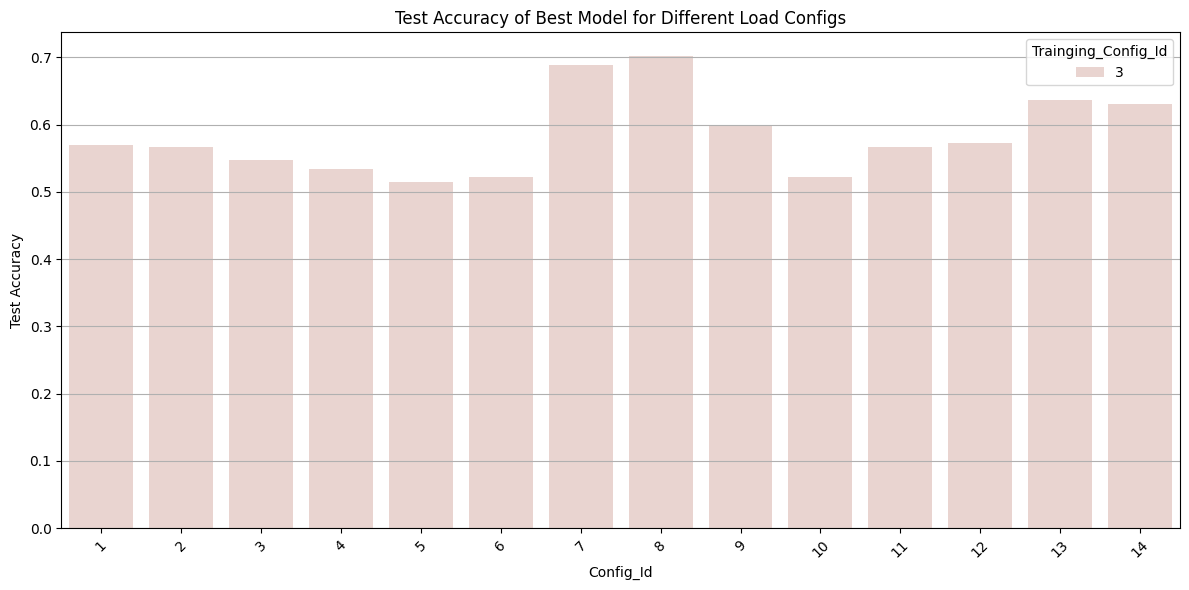

In [23]:
df_bar = df_results[df_results["Trainging_Config_Id"] == 3]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Config_Id", y="Test Acc", hue="Trainging_Config_Id")
plt.xticks(rotation=45)
plt.title("Test Accuracy of Best Model for Different Load Configs")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


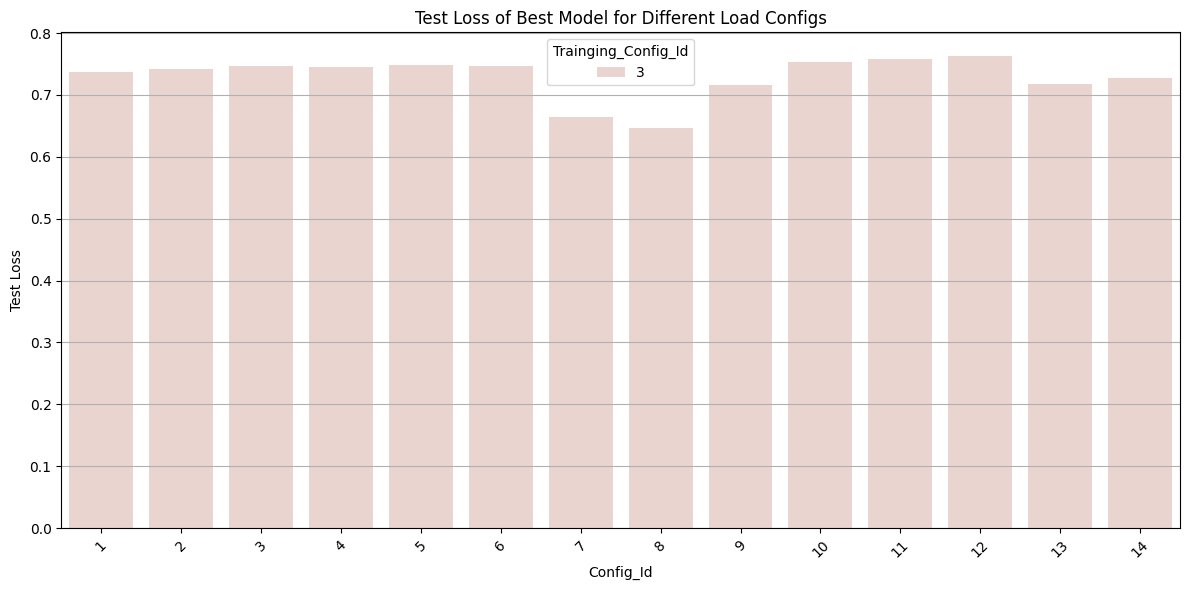

In [24]:
df_bar = df_results[df_results["Trainging_Config_Id"] == 3]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Config_Id", y="Test Loss", hue="Trainging_Config_Id")
plt.xticks(rotation=45)
plt.title("Test Loss of Best Model for Different Load Configs")
plt.ylabel("Test Loss")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


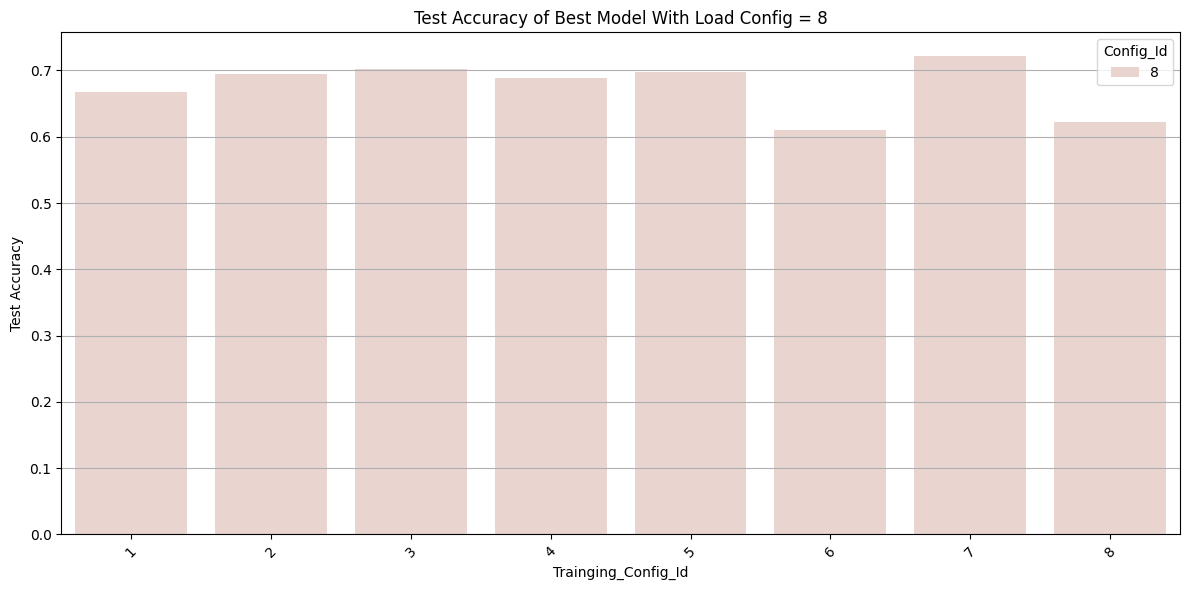

In [25]:
df_bar = df_results[df_results["Config_Id"] == 8]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Trainging_Config_Id", y="Test Acc", hue="Config_Id")
plt.xticks(rotation=45)
plt.title("Test Accuracy of Best Model With Load Config = 8")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


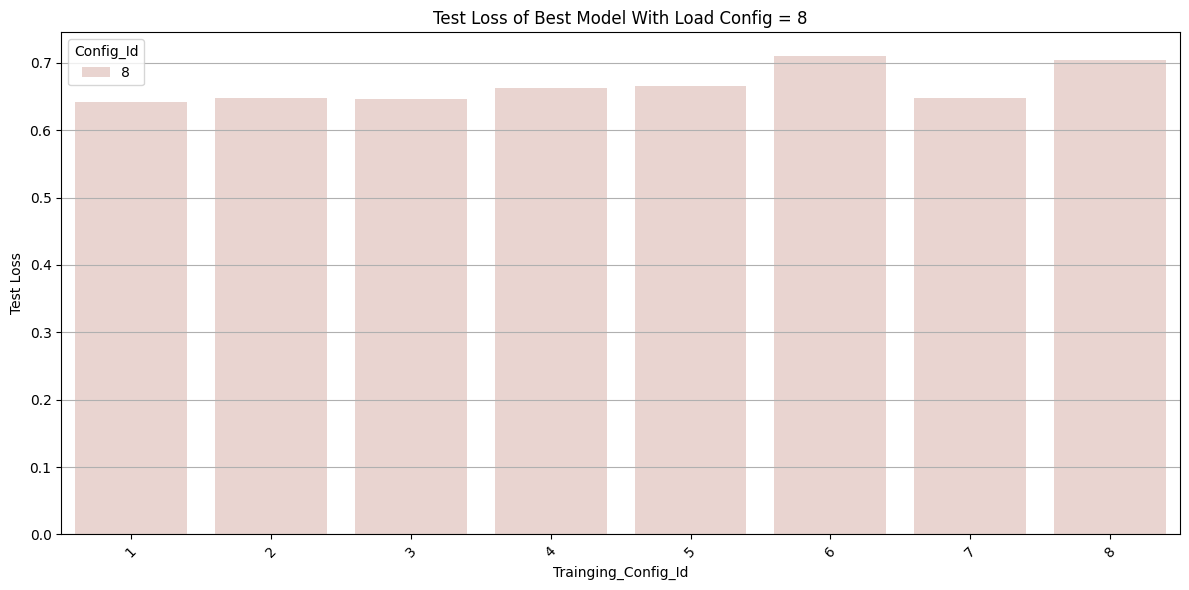

In [28]:
df_bar = df_results[df_results["Config_Id"] == 8]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_bar, x="Trainging_Config_Id", y="Test Loss", hue="Config_Id")
plt.xticks(rotation=45)
plt.title("Test Loss of Best Model With Load Config = 8")
plt.ylabel("Test Loss")
plt.tight_layout()
plt.grid(axis='y')
plt.show()


In [32]:
for idx, row in df_top.iterrows():
    print(f"Training Config ID: {row['Trainging_Config_Id']} | Load Config ID: {row['Config_Id']}")
    print(f"Test Acc: {row['Test Acc']:.4f} | Test Loss: {row['Test Loss']:.4f}")
    print(f"Train Acc: {row['Train Acc']:.4f} | Train Loss: {row['Train Loss']:.4f}")
    print(f"Best Acc: {row['best_acc']} | Best Loss: {row['best_loss']}")
    print(f"Avg Epoch Time (s): {row['Avg Epoch Time (s)']}s")
    print(f"Early Stop: {row['Early Stop Trigger']}")
    print("-" * 50)

Training Config ID: 7 | Load Config ID: 8
Test Acc: 0.7214 | Test Loss: 0.6482
Train Acc: 0.8915 | Train Loss: 0.3933
Best Acc: 0.713608 | Best Loss: 0.634959
Avg Epoch Time (s): 34.834s
Early Stop: True
--------------------------------------------------
Training Config ID: 3 | Load Config ID: 8
Test Acc: 0.7022 | Test Loss: 0.6470
Train Acc: 0.8447 | Train Loss: 0.4633
Best Acc: 0.696477 | Best Loss: 0.639316
Avg Epoch Time (s): 43.162s
Early Stop: True
--------------------------------------------------
Training Config ID: 5 | Load Config ID: 8
Test Acc: 0.6983 | Test Loss: 0.6655
Train Acc: 0.8433 | Train Loss: 0.4599
Best Acc: 0.692993 | Best Loss: 0.640721
Avg Epoch Time (s): 42.287s
Early Stop: True
--------------------------------------------------
Training Config ID: 2 | Load Config ID: 8
Test Acc: 0.6946 | Test Loss: 0.6481
Train Acc: 0.8390 | Train Loss: 0.4723
Best Acc: 0.693767 | Best Loss: 0.637611
Avg Epoch Time (s): 33.911s
Early Stop: False
------------------------------

In [11]:
def show_plot_column(df, Load_Config_Id, Trainging_Config_Id, column_name):
    for idx, row in df.iterrows():
        training_config = row["Trainging_Config_Id"]
        load_config = row['Config_Id']
        img_path = row[column_name]
        if training_config == Trainging_Config_Id and load_config == Load_Config_Id and pd.notnull(img_path) and os.path.exists(img_path):
            display(Image(filename=img_path))
            return
    print(f"can't find {column_name} for model {row['Model']} with load Config {row['Config_Id']} Traning Config {row['Trainging_Config_Id']}")

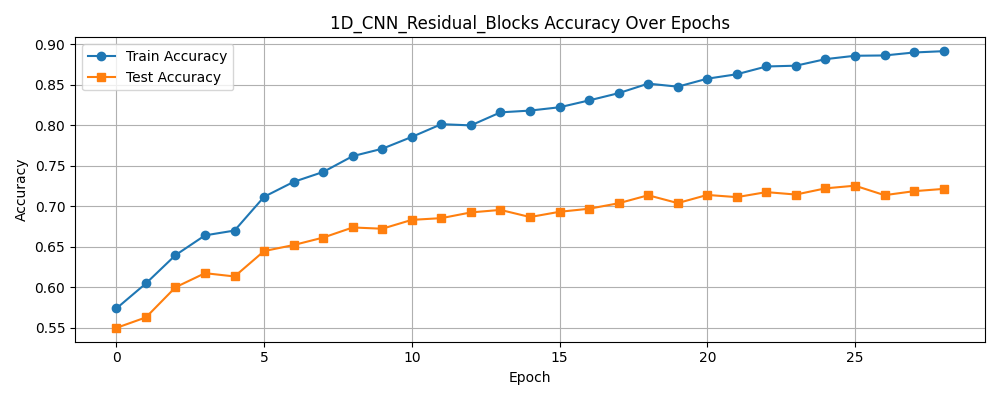

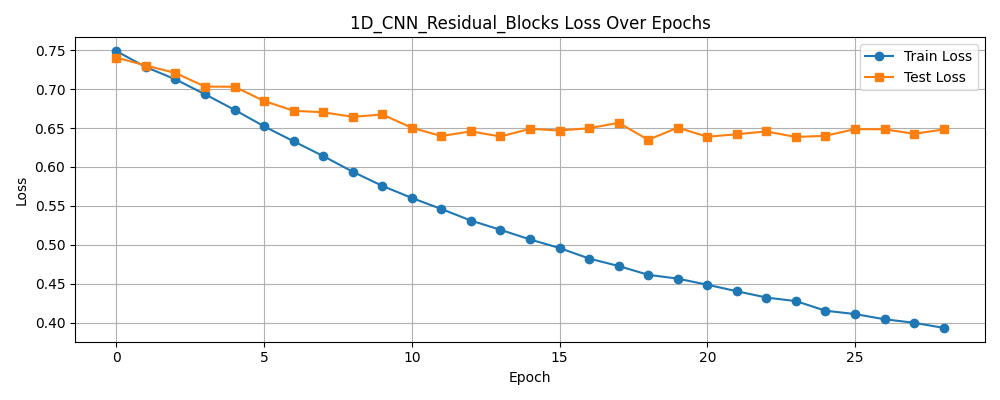

In [ ]:
show_plot_column(df_results,8,3,"Acc_plot_path")
show_plot_column(df_results,8,3,"Loss_plot_path")

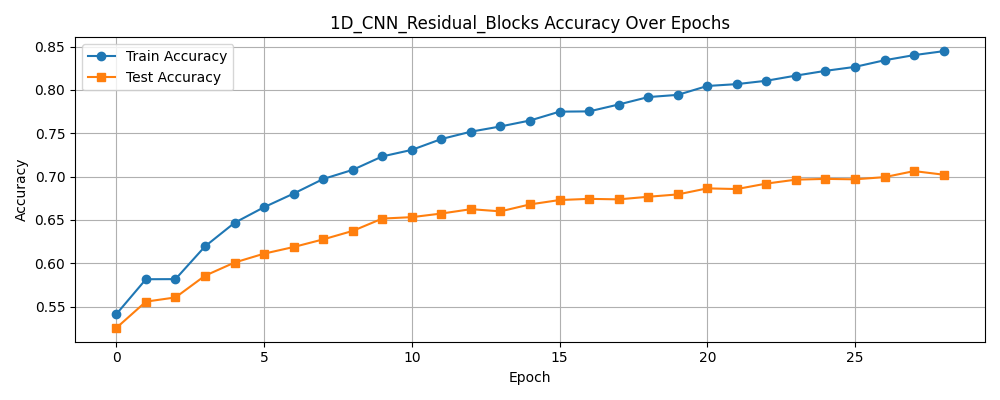

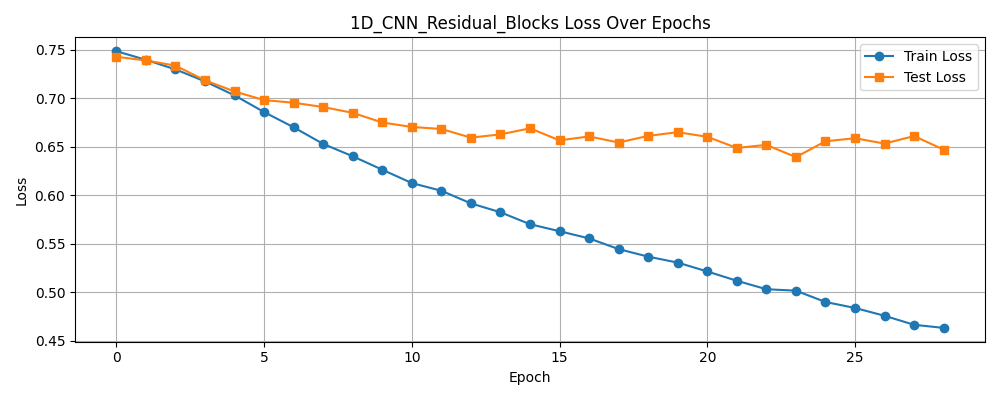

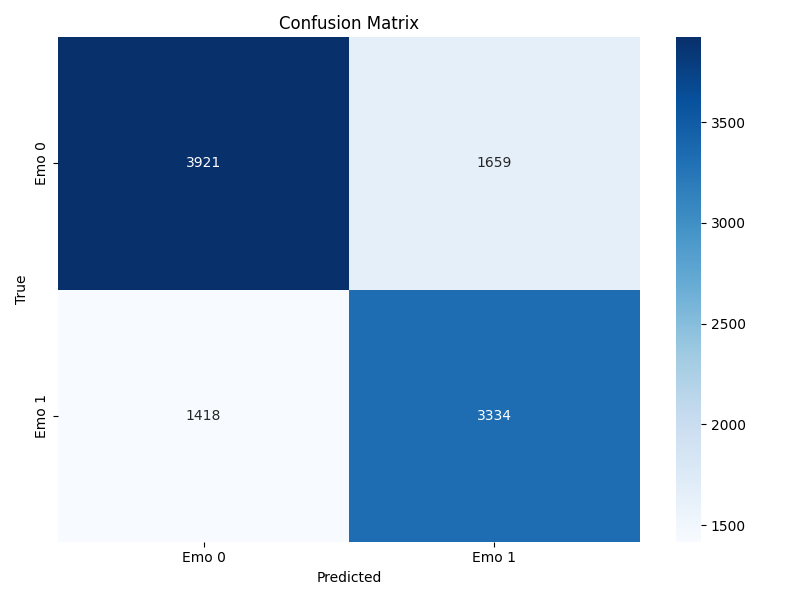

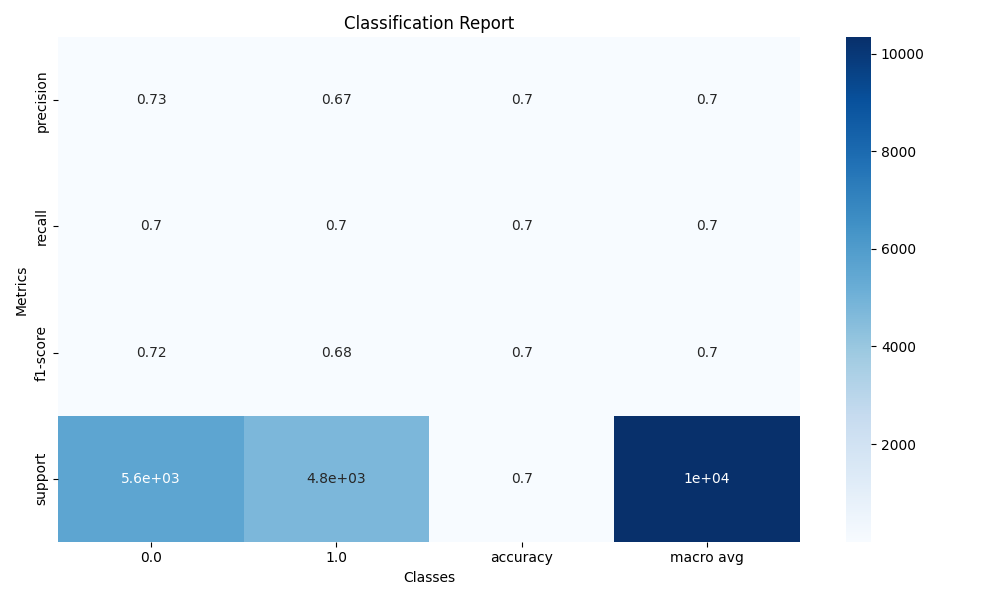

In [34]:
show_plot_column(df_results,8,3,"Acc_plot_path")
show_plot_column(df_results,8,3,"Loss_plot_path")
show_plot_column(df_results,8,3,"CM_plot_path")
show_plot_column(df_results,8,3,"CR_plot_path")

In [ ]:
show_plot_column(df_results,8,3,"Acc_plot_path")
show_plot_column(df_results,8,3,"Loss_plot_path")